# Start Here: How Large Language Models Actually Work

> **Who is this for:** complete beginners who have used a chatbot and want to know what is going on inside, without needing an API key or a GPU.
>
> **What you will learn:**
> - the one core idea: an LLM is a **next-token predictor**
> - how to look at a real model's probabilities and generate text **by hand**, one token at a time
> - **sampling**: greedy decoding, temperature, top-k and top-p, and why answers vary
> - **chat models**: system/user/assistant roles, chat templates, the context window and token costs
> - build and train a **tiny GPT from scratch** in PyTorch and look inside its attention
> - the main **limitations** (hallucination, knowledge cutoff, randomness) and how RAG, tools and fine-tuning help
> - how all of this maps onto calling a hosted LLM API
>
> **Prerequisites:** [Start Here: Turning Text into Numbers](../07_NLP/00_start_here_text_to_numbers.ipynb) (tokens and embeddings). Helpful but optional: [neural network fundamentals](../05_Deep_Learning/01_neural_network_fundamentals.ipynb).
>
> **Time needed:** about 1.5-2 hours to read and play (the notebook itself runs in about 2-5 minutes on a laptop CPU, including up to about 2 minutes of training).
>
> **Runs on:** CPU, no API key, no internet. We use **Qwen2.5-0.5B-Instruct**, a small open model (about half a billion parameters) that is already cached on this machine.

## 0. Setup

We load the tokenizer and the model from the local cache. A **parameter** is one adjustable number inside the model (a "knob" set during training); this model has about 494 million of them.

In [1]:
import os, time, math, random, warnings                # standard-library helpers
_hf_hub = os.environ.get("HF_HUB_CACHE") or os.path.join(os.environ.get("HF_HOME") or os.path.join(os.path.expanduser("~"), ".cache", "huggingface"), "hub")
if all(os.path.isdir(os.path.join(_hf_hub, "models--" + m.replace("/", "--"))) for m in ['Qwen/Qwen2.5-0.5B-Instruct']):
    os.environ.setdefault("HF_HUB_OFFLINE", "1")   # model already downloaded: never touch the internet
# (if it is not downloaded yet, the first run downloads it once from Hugging Face)
os.environ["TOKENIZERS_PARALLELISM"] = "false"         # silence a harmless warning
warnings.filterwarnings("ignore")                      # keep the output readable

import numpy as np                                     # numbers and arrays
import pandas as pd                                    # tables
import matplotlib.pyplot as plt                        # plots
import torch                                           # deep-learning library
import torch.nn as nn                                  # neural-network building blocks
import torch.nn.functional as F                        # functions like softmax
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()                       # hide non-essential messages
hf_logging.disable_progress_bar()                      # hide "Loading weights" bars

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)   # reproducible results

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_NAME)                     # text <-> token ids
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32)  # CPU, full precision
model.eval()                                                        # "use" mode, not training mode

n_params = sum(p.numel() for p in model.parameters())               # count every number in the model
print(f"Loaded {MODEL_NAME} with {n_params / 1e6:.0f} million parameters")

Loaded Qwen/Qwen2.5-0.5B-Instruct with 494 million parameters


**What just happened?**

We loaded two things:
- the **tokenizer**, which converts text to token ids and back (you met it in the previous notebook), and
- the **model**, a neural network with roughly 494 million parameters. Big commercial models have far more, but they work on exactly the same principle.

`model.eval()` switches the model into "inference" mode (just using it, not training it).

## 1. The core idea: predict the next token

An LLM does **one** thing: given some tokens, it outputs a **probability for every possible next token** in its vocabulary. That's it.

```
   "The capital of France is"  ──►  [ LLM ]  ──►   " Paris"   30%
                                                    " ______"  12%
                                                    " located"  4%
                                                     ... (151,000+ options, all adding up to 100%)
```

To write a whole answer, it repeats: pick a token, glue it onto the text, predict again. Everything a chatbot does (answering, coding, summarizing) comes out of this loop.

### Step 1: tokenize a prompt
A **prompt** is the text we give the model.

In [2]:
prompt = "The capital of France is"
ids = tok.encode(prompt)                               # text -> list of token ids
pd.DataFrame({"token id": ids,
              "token text": [repr(tok.decode([i])) for i in ids]})  # repr() makes spaces visible

,token id,token text
0,785,'The'
1,6722,' capital'
2,315,' of'
3,9625,' France'
4,374,' is'


**What just happened?** Our 5-word prompt became 5 tokens. Notice the leading spaces (`' capital'`, `' of'`): as we saw before, the space belongs to the following word.

### Step 2: ask the model for next-token probabilities

The model outputs one raw score per vocabulary token, called a **logit**. Higher means "more likely". **Softmax** is a function that turns these scores into probabilities between 0 and 1 that add up to exactly 1.

In [3]:
@torch.no_grad()                                       # we are not training: skip gradient bookkeeping
def next_token_logits(token_ids):
    out = model(torch.tensor([token_ids]))             # run the model on a batch of 1 sequence
    return out.logits[0, -1]                           # scores for the token AFTER the last one

logits = next_token_logits(ids)
probs = torch.softmax(logits, dim=-1)                  # scores -> probabilities that sum to 1
print("One score per vocabulary entry:", logits.shape[0])
print("Probabilities add up to:", round(probs.sum().item(), 4))

top_p, top_i = probs.topk(10)                          # the 10 most likely next tokens
top10 = pd.DataFrame({"next token": [repr(tok.decode([i])) for i in top_i.tolist()],
                      "probability": top_p.numpy().round(3)})
top10

One score per vocabulary entry: 151936
Probabilities add up to: 1.0001


,next token,probability
0,' Paris',0.302
1,' ______',0.123
2,':\n',0.066
3,':\n\n',0.058
4,' __',0.048
5,' ____',0.045
6,' located',0.043
7,' the',0.035
8,' (',0.024
9,' [',0.021


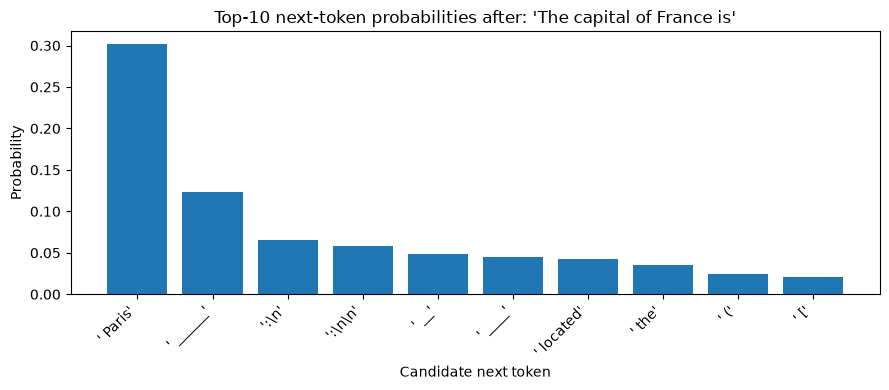

In [4]:
plt.figure(figsize=(9, 4))
plt.bar(top10["next token"], top10["probability"], color="tab:blue")
plt.title(f"Top-10 next-token probabilities after: {prompt!r}")
plt.xlabel("Candidate next token"); plt.ylabel("Probability")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

**What just happened?**

- `' Paris'` is the clear favourite, but with only about **30%** probability, not 100%.
- The other candidates are not "wrong capitals"; they are other ways the *text* could continue. `' ______'` and `' __'` are blanks, as in a quiz worksheet ("The capital of France is ______."), and `':\n'` would start a list. The model learned from all kinds of text, including fill-in-the-blank exercises.
- We printed only 10 of the 151,936 options; all of them together add up to 1 (the tiny `1.0001` is just rounding in the computer's arithmetic).

> 💡 **Tip:** the model never "looks up" an answer. It produces a *probability distribution* (a list of options with their chances) learned from patterns in its training text.

### Step 3: generate text by hand

Now we write the generation loop ourselves. At each step we pick the **most likely** token (this is called **greedy decoding**), append it, and run the model again. We do 15 steps and print each one.

In [5]:
text_ids = tok.encode("Once upon a time, a little robot")   # starting prompt
print("Start:", tok.decode(text_ids))
for step in range(1, 16):                              # 15 generation steps
    p = torch.softmax(next_token_logits(text_ids), dim=-1)
    best = int(p.argmax())                             # greedy: the single most likely token
    text_ids.append(best)                              # glue it onto the text
    print(f"step {step:2d} | chose {tok.decode([best])!r:14} (p={p[best]:.2f}) | {tok.decode(text_ids)!r}")

Start: Once upon a time, a little robot
step  1 | chose ' named'       (p=0.68) | 'Once upon a time, a little robot named'


step  2 | chose ' Rob'         (p=0.06) | 'Once upon a time, a little robot named Rob'
step  3 | chose 'o'            (p=0.50) | 'Once upon a time, a little robot named Robo'


step  4 | chose ' had'         (p=0.21) | 'Once upon a time, a little robot named Robo had'
step  5 | chose ' a'           (p=0.45) | 'Once upon a time, a little robot named Robo had a'


step  6 | chose ' simple'      (p=0.04) | 'Once upon a time, a little robot named Robo had a simple'
step  7 | chose ' task'        (p=0.20) | 'Once upon a time, a little robot named Robo had a simple task'


step  8 | chose ' to'          (p=0.31) | 'Once upon a time, a little robot named Robo had a simple task to'
step  9 | chose ' do'          (p=0.26) | 'Once upon a time, a little robot named Robo had a simple task to do'


step 10 | chose '.'            (p=0.51) | 'Once upon a time, a little robot named Robo had a simple task to do.'
step 11 | chose ' He'          (p=0.54) | 'Once upon a time, a little robot named Robo had a simple task to do. He'


step 12 | chose ' had'         (p=0.50) | 'Once upon a time, a little robot named Robo had a simple task to do. He had'
step 13 | chose ' to'          (p=0.94) | 'Once upon a time, a little robot named Robo had a simple task to do. He had to'


step 14 | chose ' find'        (p=0.06) | 'Once upon a time, a little robot named Robo had a simple task to do. He had to find'
step 15 | chose ' the'         (p=0.37) | 'Once upon a time, a little robot named Robo had a simple task to do. He had to find the'


**What just happened?**

Each line is one trip through the model. The model chose the most likely token, we glued it onto the text, and the *whole* text went back in for the next prediction. That is genuinely all that "generation" is.

In our run the model wrote *"...a little robot named Robo had a simple task to do. He had to find the"*. A few things to notice:
- The name "Robo" took **two** tokens (`' Rob'` + `'o'`).
- The `p=` value shows how confident the model was. `' to'` after "He had" was near-certain (p≈0.94), while `' Rob'` (p≈0.06) and `' simple'` (p≈0.04) were picked even though they had low probability: greedy only needs the *highest* option, and here many options were almost equally unlikely.

> 💡 **Tip:** re-reading the whole text at every step is wasteful. Real systems keep a **KV cache** (a memory of the work already done for earlier tokens) so each new step only processes the newest token. Our `generate` helper below uses it. See [13_inference_optimization.ipynb](13_inference_optimization.ipynb) for more.

## 2. Sampling: why the same question can get different answers

Greedy decoding always picks the top token, so it is **deterministic** (same input → same output) but can be dull or repetitive. Instead, we can **sample**: roll a weighted dice using the probabilities. Three knobs control the dice:

| Knob | What it does | Typical effect |
|---|---|---|
| **temperature** | divides the logits by T before softmax. T < 1 sharpens the distribution, T > 1 flattens it | low T = safe and repetitive, high T = creative and eventually nonsense |
| **top-k** | keep only the k most likely tokens, then sample | cuts off the long tail of weird tokens |
| **top-p** (nucleus) | keep the smallest set of tokens whose probabilities add up to p (e.g. 0.9) | like top-k but adapts: few tokens when confident, many when unsure |

Let's implement all three ourselves on the real logits.

In [6]:
def sample_from_logits(logits, temperature=1.0, top_k=None, top_p=None, generator=None):
    if temperature == 0:                               # temperature 0 means "greedy"
        return int(torch.argmax(logits))
    probs = torch.softmax(logits / temperature, dim=-1)        # 1) temperature reshapes the scores
    if top_k is not None:                              # 2) top-k: zero out everything outside the top k
        kth_best = torch.topk(probs, top_k).values[-1]
        probs = torch.where(probs >= kth_best, probs, torch.zeros_like(probs))
    if top_p is not None:                              # 3) top-p: keep the smallest set reaching p
        sorted_p, order = torch.sort(probs, descending=True)
        cumulative = torch.cumsum(sorted_p, dim=0)
        keep = cumulative - sorted_p < top_p           # keep a token if the ones before it are < p
        mask = torch.zeros_like(probs); mask[order[keep]] = 1.0
        probs = probs * mask
    probs = probs / probs.sum()                        # re-normalize so they add up to 1 again
    return int(torch.multinomial(probs, 1, generator=generator))   # roll the weighted dice

**What just happened?** We wrote the same sampling logic that real inference libraries use, in about 15 lines. Nothing has run yet; it is just a function. Let's first *see* what temperature does to the probabilities.

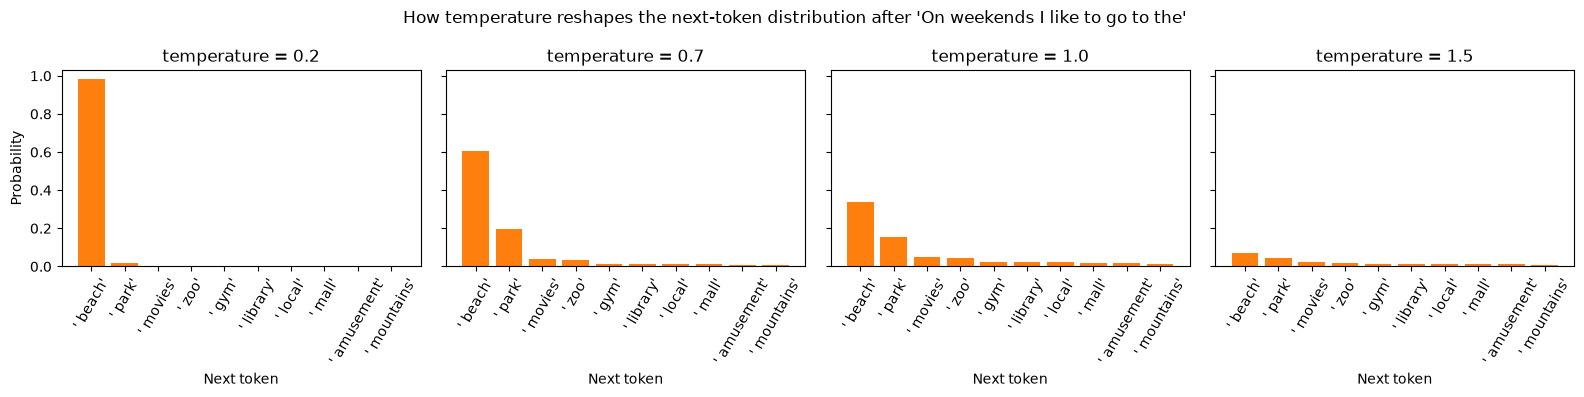

In [7]:
fav_prompt = "On weekends I like to go to the"
fav_logits = next_token_logits(tok.encode(fav_prompt))
top_ids = torch.softmax(fav_logits, -1).topk(10).indices      # same 10 tokens in every panel
labels = [repr(tok.decode([i])) for i in top_ids.tolist()]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, T in zip(axes, [0.2, 0.7, 1.0, 1.5]):
    p = torch.softmax(fav_logits / T, dim=-1)[top_ids]           # probabilities after temperature
    ax.bar(labels, p.numpy(), color="tab:orange")
    ax.set_title(f"temperature = {T}"); ax.set_xlabel("Next token")
    ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("Probability")
fig.suptitle(f"How temperature reshapes the next-token distribution after {fav_prompt!r}")
plt.tight_layout(); plt.show()

**What just happened?**

The four panels show the **same 10 tokens**, only the temperature changes:
- **T = 0.2:** `' beach'` gets almost all the probability (close to 1.0). Sampling at this temperature behaves almost like greedy.
- **T = 0.7:** `' beach'` still leads (about 0.6), with `' park'` a clear second.
- **T = 1.0:** the model's original probabilities (beach about 0.34, park about 0.15).
- **T = 1.5:** everything is flattened; even the top token has well under 0.1. The remaining probability has flowed to the thousands of tokens *outside* this top-10, so weird tokens now get picked much more often.

Now let's generate real text with each setting. The helper below runs the same loop as before, but uses the **KV cache** for speed and stops at the model's end-of-text token. We use a separate random **generator** with a fixed seed for each sample, so the notebook is reproducible.

In [8]:
STOP_IDS = {tok.convert_tokens_to_ids(t) for t in ["<|im_end|>", "<|endoftext|>"]}  # "I'm done" tokens

@torch.no_grad()
def generate(prompt_text, max_new_tokens=20, temperature=0.0, top_k=None, top_p=None, seed=0):
    gen = torch.Generator().manual_seed(seed)          # private dice, so results are reproducible
    ids = tok(prompt_text, return_tensors="pt").input_ids
    out = model(ids, use_cache=True)                   # read the prompt once
    new_tokens = []
    for _ in range(max_new_tokens):
        nxt = sample_from_logits(out.logits[0, -1], temperature, top_k, top_p, gen)
        if nxt in STOP_IDS:                            # the model says it is finished
            break
        new_tokens.append(nxt)
        out = model(torch.tensor([[nxt]]), past_key_values=out.past_key_values, use_cache=True)  # only the new token
    return tok.decode(new_tokens)

start = "My favourite thing to do on a rainy day is"
print("greedy, run 1:", repr(generate(start)))
print("greedy, run 2:", repr(generate(start)))

greedy, run 1: ' to go to the park. I like to go there because it is a great place to relax and'


greedy, run 2: ' to go to the park. I like to go there because it is a great place to relax and'


**What just happened?** Greedy decoding gave **exactly the same** continuation twice. With temperature 0 there is no dice roll, so the output is fully determined by the prompt.

In [9]:
settings = [("temperature 0.2", dict(temperature=0.2)),
            ("temperature 0.7", dict(temperature=0.7)),
            ("temperature 1.5", dict(temperature=1.5)),
            ("top-k = 5", dict(temperature=1.0, top_k=5)),
            ("top-p = 0.9", dict(temperature=1.0, top_p=0.9))]
t0 = time.time()
for name, kwargs in settings:
    print(f"--- {name}")
    for seed in range(3):                              # 3 different dice rolls per setting
        print(f"  seed {seed}: {generate(start, max_new_tokens=15, seed=seed, **kwargs)!r}")
print(f"(took {time.time() - t0:.0f} s)")

--- temperature 0.2


  seed 0: ' to go to the beach. I love the feeling of the sand between my'


  seed 1: ' to go to the park. The park is a place where people can go'


  seed 2: ' to go to the beach. I have a favorite place to go to the'
--- temperature 0.7


  seed 0: ' go shopping. On Thursday evening, I go shopping for a bunch of flowers'


...

  seed 1: ' go out for a walk. The first thing I do is take a walk'


  seed 2: ' to sit in my living room with my cat and play with her. But'
--- top-p = 0.9


  seed 0: ' go shopping. On Thursday evening, when the prices started to rise and the'


  seed 1: ':\nFor how many times is the number 1000 a factor'


  seed 2: ' to walk to the beach. Last summer, I walked my dog for many'
(took 38 s)


**What just happened?**

Read the outputs above (all from the same prompt):
- **Temperature 0.2:** all three samples are sensible and similar (the beach or the park), close to the greedy answer.
- **Temperature 0.7:** more variety: shopping, a walk to the beach, and in one sample the model switched into a multiple-choice quiz format ("A. make dinner B. read a book..."), a pattern it saw in its training text.
- **Temperature 1.5:** nonsense: random English words mixed with Chinese characters and programming words. The flattened distribution lets rare tokens win.
- **Top-k = 5:** varied but sensible (a hike, a walk, playing with a cat), because only the 5 most likely tokens are ever allowed.
- **Top-p = 0.9:** mostly sensible, though one sample drifted into a maths question. Seeds 0 and 2 start the same way as at temperature 0.7, because the same dice rolls landed on the same likely tokens at first.

The `took ... s` line shows how long this cell ran; on a CPU each new token takes a noticeable fraction of a second (more if the computer is busy with other work).

> ⚠️ **Common mistake:** thinking temperature 0 makes a model *correct*. It only makes it *consistent*. A wrong answer at temperature 0 is wrong every time.

> 💡 **Tip:** a common starting point is a low temperature (around 0 to 0.3) for factual or structured tasks, and a moderate one (around 0.7 to 1.0) for brainstorming or creative writing. Check your provider's documentation for its defaults.

### Top-k and top-p on the "capital of France" example

How many candidate tokens survive each filter? When the model is confident, top-p keeps very few tokens; when it is unsure, it keeps many.

In [10]:
def survivors(logits, top_k=None, top_p=None):
    probs = torch.softmax(logits, -1)
    if top_k is not None:
        return top_k                                   # top-k always keeps exactly k tokens
    sorted_p = torch.sort(probs, descending=True).values
    return int(((torch.cumsum(sorted_p, 0) - sorted_p) < top_p).sum())   # same rule as in our sampler

rows = []
for name, lg in [("The capital of France is", logits), (fav_prompt, fav_logits)]:
    rows.append({"prompt": name, "top-k=5 keeps": survivors(lg, top_k=5),
                 "top-p=0.5 keeps": survivors(lg, top_p=0.5), "top-p=0.9 keeps": survivors(lg, top_p=0.9)})
pd.DataFrame(rows)

,prompt,top-k=5 keeps,top-p=0.5 keeps,top-p=0.9 keeps
0,The capital of France is,5,4,25
1,On weekends I like to go to the,5,3,113


**What just happened?**

- **Top-k** keeps exactly 5 tokens in both cases, no matter how the probabilities look.
- **Top-p = 0.9** adapts: for "The capital of France is" 25 tokens are enough to cover 90% of the probability, but for the more open-ended "On weekends I like to go to the" it needs over 100 tokens, because after the top few places there is a long tail of small possibilities.
- **Top-p = 0.5** keeps only a handful of tokens in both cases (4 and 3).

## 3. Chat models: roles, templates, context and cost

### Roles and the chat template

A **chat model** (or *instruct* model) is a base LLM that has been further trained to follow instructions in a conversation. Conversations are written as a list of messages, each with a **role**:

| Role | Who writes it | Purpose |
|---|---|---|
| `system` | the app developer | sets behaviour and rules ("You are a helpful tutor...") |
| `user` | the person | the question or request |
| `assistant` | the model | its previous replies (so it can see the conversation so far) |

But the model only understands one long stream of tokens. A **chat template** turns the message list into that stream, using special marker tokens. Let's print it.

In [11]:
messages = [
    {"role": "system", "content": "You are a friendly tutor. Answer in one short sentence."},
    {"role": "user", "content": "What is a token?"},
]
templated = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)  # list -> one string
print(templated)

<|im_start|>system
You are a friendly tutor. Answer in one short sentence.<|im_end|>
<|im_start|>user
What is a token?<|im_end|>
<|im_start|>assistant



**What just happened?**

The messages became a single string. Each message is wrapped in `<|im_start|>role ... <|im_end|>` markers (this particular format is the one Qwen uses; other model families use different markers, which is why you always use the tokenizer's own `apply_chat_template` instead of writing it by hand). `add_generation_prompt=True` added an opening `<|im_start|>assistant` at the end: an invitation for the model to continue *as the assistant*.

Now let the model continue that string, using our own `generate` function:

In [12]:
answer = generate(templated, max_new_tokens=50)       # greedy continuation of the chat string
print("Assistant:", answer)

Assistant: A token is a small, portable unit of currency or value.


**What just happened?** When we ran this, the model answered *"A token is a small, portable unit of currency or value."* That is a real meaning of "token" (like an arcade token), but not the one we meant! Nothing in our messages said we were talking about language models, so the model picked the everyday meaning. Lesson: an LLM only knows what is in its context, so give it enough context (for example, a system prompt saying "You are a tutor for an AI course").

A chatbot is just this: template the conversation, predict tokens until the end marker, show the result.

### The context window

The **context window** is the maximum number of tokens the model can look at in one go: system prompt + conversation history + documents + its own reply. Anything beyond it must be cut or summarized.

In [13]:
print("This model's maximum positions (context window):", model.config.max_position_embeddings)

for name, text in [("one-line question", "What is a token?"),
                   ("our templated chat", templated),
                   ("a 300-word essay (fake)", "word " * 300)]:
    print(f"{name:25} -> {len(tok.encode(text)):5d} tokens")

This model's maximum positions (context window): 32768
one-line question         ->     5 tokens
our templated chat        ->    30 tokens
a 300-word essay (fake)   ->   301 tokens


**What just happened?**

- This model can handle up to **32,768** token positions in one go (prompt + reply together).
- A one-line question is only 5 tokens, but the *templated* chat (system prompt, role markers and question) is 30 tokens: the template adds overhead.
- 300 repetitions of `"word "` came to 301 tokens. Real prose usually needs somewhat more tokens than words, because longer or rarer words are split into pieces.

> ⚠️ **Common mistake:** forgetting that the chat template and system prompt also use tokens. Always count the *templated* string, not just the user's question.

### Why longer prompts cost more

Hosted LLM APIs usually charge **per token**, often with separate prices for **input** tokens (what you send) and **output** tokens (what the model writes), quoted per million tokens. A chatbot also has no memory of its own: the app re-sends the **whole conversation** on every turn, so input tokens grow turn after turn.

The prices below are **made up for teaching**. Real prices vary widely between providers and models and change often, so always check the provider's current pricing page.

In [14]:
PRICE_IN_PER_M = 0.50                                  # MADE-UP example: $ per 1 million input tokens
PRICE_OUT_PER_M = 2.00                                 # MADE-UP example: $ per 1 million output tokens

def cost(n_in, n_out):
    return n_in / 1e6 * PRICE_IN_PER_M + n_out / 1e6 * PRICE_OUT_PER_M

turn_q = "Can you explain that again with a different example?"   # a typical user message
turn_a = "Sure! " + "Here is another example sentence. " * 15     # a typical ~100-token reply
history = [{"role": "system", "content": "You are a helpful tutor."}]
rows = []
for turn in range(1, 11):                              # simulate a 10-turn chat
    history.append({"role": "user", "content": turn_q})
    sent_text = tok.apply_chat_template(history, tokenize=False, add_generation_prompt=True)  # whole history is sent
    n_in = len(tok.encode(sent_text))                  # count its tokens
    n_out = len(tok.encode(turn_a))
    history.append({"role": "assistant", "content": turn_a})
    rows.append({"turn": turn, "input tokens": n_in, "output tokens": n_out, "cost ($)": cost(n_in, n_out)})
chat_costs = pd.DataFrame(rows)
print(chat_costs.to_string(index=False, formatters={"cost ($)": "{:.6f}".format}))
print(f"Total for 10 turns: ${chat_costs['cost ($)'].sum():.5f}  |  x 1 million conversations: ${chat_costs['cost ($)'].sum() * 1e6:,.0f}")

 turn  input tokens  output tokens cost ($)
    1            29             93 0.000200
    2           142             93 0.000257
    3           255             93 0.000313
    4           368             93 0.000370
    5           481             93 0.000427
    6           594             93 0.000483
    7           707             93 0.000539
    8           820             93 0.000596
    9           933             93 0.000652
   10          1046             93 0.000709
Total for 10 turns: $0.00455  |  x 1 million conversations: $4,547


**What just happened?**

- The user's message and the reply are the same size every turn (the reply is about 93 tokens), but the **input** grows from about 29 tokens at turn 1 to over 1,000 tokens at turn 10, because the whole history is re-sent.
- So the cost per turn more than triples by turn 10. Per conversation it is a tiny fraction of a cent with these made-up prices, but multiplied by a million conversations it reaches a few thousand dollars.

> 💡 **Tip:** to control cost, keep system prompts short, trim or summarize old history, retrieve only the relevant parts of documents (that is what RAG does) and set a maximum output length.

## 4. Build a tiny GPT from scratch

Qwen is a **transformer**, the neural-network design behind nearly all modern LLMs. To demystify it, we will build a *tiny* one ourselves and train it on a few nursery-style rhymes written for this notebook. It works on **characters** (each letter is a token) to keep things simple.

The parts we will build, from bottom to top:

```
 characters  "t h e   c a t"
      │
 [token embedding]       each character id -> a vector of numbers (what the character is)
      +
 [positional embedding]  each position 0,1,2,... -> a vector (where the character is)
      │
 ┌── transformer block (x2) ─────────────────────────────────────────┐
 │ [self-attention + causal mask]  each position looks back at        │
 │                                 earlier positions and mixes info   │
 │ [MLP]                           a small per-position neural net    │
 └────────────────────────────────────────────────────────────────────┘
      │
 [logits]                one score per character in the vocabulary -> next-character prediction
```

In [15]:
RHYMES = 'the little cat sat on the mat,\nshe had a hat and that was that.\nthe little dog ran in the fog,\nhe found a frog upon a log.\n\nthe sun is high, the sky is blue,\nthe birds can fly and so can you.\nthe moon is round, the stars are bright,\nwe make no sound and say good night.\n\nthe rain will fall on the garden wall,\nthe tree is tall, the flowers small.\nthe wind will blow, the river flow,\nthe seeds will grow when the farmers sow.\n\none, two, three, a bee in a tree,\nfour, five, six, a hen and her chicks.\nseven, eight, nine, the weather is fine,\nten, ten, ten, let us count again.\n\nthe baker bakes a cake for me,\nthe cake is sweet, as sweet can be.\nthe fisher rows his boat to sea,\nand brings a fish home for our tea.\n\nthe mouse ran up the kitchen clock,\nthe clock went tick, the clock went tock.\nthe mouse ran down and hid in a sock,\nand slept all day behind the lock.\n\nthe cow says moo, the sheep says baa,\nthe duck says quack, near and far.\nthe pig says oink, the horse says neigh,\nthey sing their songs at the end of day.\n\na little star up in the sky,\nit winks at me as I walk by.\nI wish I knew the reason why,\nthe little star is up so high.\n\nthe boat is red, the sail is white,\nit sails away into the night.\nthe waves are big, the waves are small,\nthe boat comes home, and that is all.\n\nthe snow is cold, the snow is deep,\nthe bears are old and fast asleep.\nthe fire is warm, the soup is hot,\nwe eat it all from the little pot.\n\nthe cat and the dog and the frog on the log,\nwent out for a walk in the morning fog.\nthey met a bee who sat in a tree,\nand all of them went home for tea.\n\nthe rain is gone, the sun is out,\nthe children run and jump and shout.\nthe grass is green, the sky is clear,\nthe best of days is finally here.\n\nthe owl at night will sit and stare,\nat the silver moon and the cool night air.\nthe fox will creep, the deer will sleep,\nthe stars will watch the hills and keep.\n\nthe train goes fast along the track,\nit goes away and then comes back.\nthe bus is slow, the car is quick,\nthe bike goes round with a click click click.\n\na cup of milk, a slice of bread,\na story read, and off to bed.\nthe lamp is low, the room is still,\nthe moon looks in from the window sill.\n\nthe hen is red, the hen is fat,\nshe sat all day upon her hat.\nthe cat came by and said hello,\nthe hen said no and off to go.\n\nthe kite is up, the kite is high,\nit dances in the windy sky.\nthe string is long, the boy is small,\nhe holds it tight and will not fall.\n\nthe bee will buzz, the bee will hum,\nthe bee will find a flower to come.\nthe honey is sweet, the honey is gold,\nwe keep it safe for when it is cold.\n\nthe frog will jump, the frog will hop,\nthe frog will sit and never stop.\nhe jumps so high, he jumps so far,\nhe jumps right up to touch a star.\n\nthe old man sat beside the sea,\nhe drank a cup of mint green tea.\nthe gulls flew down, the gulls flew round,\nand made a happy, noisy sound.\n\na dog, a log, a frog, a fog,\na cat, a hat, a mat, a bat.\na bee, a tree, a sea, a key,\nand that is all, from you and me.\n\nthe clock goes tick, the clock goes tock,\nthe hen goes cluck, the farm wakes up.\nthe cow goes out, the sheep come in,\nthe day is done, the night begins.\n\nthe little fish swims in the pool,\nit swims all day, it swims to school.\nthe water is cool, the water is blue,\nthe fish is happy, and so are you.\n'

chars = sorted(set(RHYMES))                            # our vocabulary: every distinct character
stoi = {c: i for i, c in enumerate(chars)}             # character -> id
itos = {i: c for c, i in stoi.items()}                 # id -> character
encode = lambda s: [stoi[c] for c in s]                # text -> ids
decode = lambda ids: "".join(itos[i] for i in ids)     # ids -> text

data = torch.tensor(encode(RHYMES))                    # the whole text as one long list of ids
split = int(0.9 * len(data))                           # 90% to train on, 10% to check on
train_data, val_data = data[:split], data[split:]
print(f"{len(RHYMES)} characters of text, vocabulary of {len(chars)} characters")
print("Vocabulary:", repr("".join(chars)))
print(RHYMES[:120])

3303 characters of text, vocabulary of 31 characters
Vocabulary: '\n ,.Iabcdefghijklmnopqrstuvwxyz'
the little cat sat on the mat,
she had a hat and that was that.
the little dog ran in the fog,
he found a frog upon a lo


**What just happened?** Our training text is about 3 kilobytes of simple rhymes. The vocabulary is tiny (a few dozen characters: letters, space, newline and punctuation), compared with about 151,000 tokens for Qwen. We keep the last 10% of the text aside as **validation** data, to check that the model learns patterns rather than just memorizing.

### The causal mask

When predicting the next character, the model must not peek at the future. A **causal mask** is a triangle of 1s and 0s: row *i* says which positions token *i* may look at (only itself and earlier ones).

In [16]:
print(torch.tril(torch.ones(5, 5)).int())             # lower-triangular matrix: 1 = allowed to look

tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)


**What just happened?** Row 0 (the first token) can only see itself; row 4 (the fifth token) can see all five. Inside attention, the 0 entries are set to minus infinity before softmax, so they get exactly 0% attention.

### The model code

Every class below is labelled with the part of the diagram it implements.

In [17]:
BLOCK = 64        # context window: how many characters the model can look back at
EMBED = 48        # size of each embedding vector
HEADS = 4         # number of attention heads (parallel "looks" at the context)
LAYERS = 2        # number of transformer blocks
DROPOUT = 0.2     # randomly switch off 20% of signals during training (reduces memorizing)

class SelfAttentionHead(nn.Module):                    # SELF-ATTENTION (one head) with CAUSAL MASK
    def __init__(self, head_size):
        super().__init__()
        self.query = nn.Linear(EMBED, head_size, bias=False)   # "what am I looking for?"
        self.key = nn.Linear(EMBED, head_size, bias=False)     # "what do I contain?"
        self.value = nn.Linear(EMBED, head_size, bias=False)   # "what do I pass on?"
        self.register_buffer("mask", torch.tril(torch.ones(BLOCK, BLOCK)))
        self.dropout = nn.Dropout(DROPOUT)
    def forward(self, x):
        T = x.shape[1]                                          # current sequence length
        scores = self.query(x) @ self.key(x).transpose(-2, -1) / math.sqrt(self.key.out_features)
        scores = scores.masked_fill(self.mask[:T, :T] == 0, float("-inf"))  # no peeking at the future
        self.attn = torch.softmax(scores, dim=-1)               # attention weights (saved for plotting)
        return self.dropout(self.attn) @ self.value(x)          # weighted mix of earlier positions

class Block(nn.Module):                                # one TRANSFORMER BLOCK
    def __init__(self):
        super().__init__()
        self.heads = nn.ModuleList([SelfAttentionHead(EMBED // HEADS) for _ in range(HEADS)])
        self.proj = nn.Linear(EMBED, EMBED)                     # combine the heads
        self.mlp = nn.Sequential(nn.Linear(EMBED, 4 * EMBED), nn.GELU(),
                                 nn.Linear(4 * EMBED, EMBED), nn.Dropout(DROPOUT))   # MLP
        self.norm1, self.norm2 = nn.LayerNorm(EMBED), nn.LayerNorm(EMBED)  # keep numbers well-scaled
    def forward(self, x):
        x = x + self.proj(torch.cat([h(self.norm1(x)) for h in self.heads], dim=-1))  # attention + shortcut
        return x + self.mlp(self.norm2(x))                      # MLP + shortcut

class TinyGPT(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, EMBED)        # TOKEN EMBEDDING
        self.pos_emb = nn.Embedding(BLOCK, EMBED)               # POSITIONAL EMBEDDING
        self.blocks = nn.Sequential(*[Block() for _ in range(LAYERS)])
        self.norm = nn.LayerNorm(EMBED)
        self.to_logits = nn.Linear(EMBED, vocab_size)           # LOGITS: one score per character
    def forward(self, idx):
        positions = torch.arange(idx.shape[1])                  # 0, 1, 2, ... T-1
        x = self.token_emb(idx) + self.pos_emb(positions)       # what + where
        return self.to_logits(self.norm(self.blocks(x)))        # (batch, T, vocab) scores

**What just happened?** We defined (but did not yet run) a complete GPT-style model in about 40 lines:
- **Token embedding:** a lookup table turning each character id into 48 numbers.
- **Positional embedding:** a second lookup table for positions 0-63, so the model knows the *order* of characters (remember: bag of words lost order!).
- **Self-attention:** each position creates a *query*, *key* and *value*. Matching queries against keys decides how much each earlier position matters; the result is a weighted mix of values. The causal mask blocks the future. We use 4 heads in parallel.
- **MLP** (multi-layer perceptron): a small neural network applied to each position separately, to "think about" what attention gathered.
- **Logits:** a final layer giving one score per character in the vocabulary.

The **shortcuts** (`x + ...`, called *residual connections*) and **LayerNorm** are standard tricks that make training stable. **Dropout** randomly switches off some signals during training only, which makes it harder for the model to simply memorize our small text.

In [18]:
torch.manual_seed(SEED)
tiny = TinyGPT(len(chars))
print(f"TinyGPT has {sum(p.numel() for p in tiny.parameters()):,} parameters")

@torch.no_grad()
def tiny_generate(start="the ", n=200, seed=0):
    tiny.eval()                                         # use mode: dropout switched off
    gen = torch.Generator().manual_seed(seed)
    idx = torch.tensor([encode(start)])
    for _ in range(n):
        logits = tiny(idx[:, -BLOCK:])[:, -1]           # only the last BLOCK characters fit
        nxt = torch.multinomial(torch.softmax(logits, -1), 1, generator=gen)   # sample (temperature 1)
        idx = torch.cat([idx, nxt], dim=1)
    return decode(idx[0].tolist())

print("BEFORE training:\n" + tiny_generate())

TinyGPT has 62,431 parameters


BEFORE training:
the rwh
ciux.ykuIu,t.qg
c
mkm
InhdI.uprn dl,xvz,q
svwyvggqlev
lI.rumhidatIdibfe.fvydtdjsffhvvqv 
pbgxofo
jsntiajqs
pqfstfetjzytynvx cnpwjebkdtokeiehrm
vd
egvtobdtds,riavqeko hankairsrdhdwv
m d,
akuxykkb
r


**What just happened?** Our TinyGPT has about 62 thousand parameters (Qwen has roughly 8,000 times more). Before training, its parameters are random, so the output is random characters: it has no idea what English looks like yet.

Let's see a deliberate mistake first: what happens if we feed more characters than the context window?

In [19]:
too_long = torch.zeros(1, BLOCK + 10, dtype=torch.long)   # 74 characters, but the window is 64
try:
    tiny(too_long)
except IndexError as err:
    print("IndexError:", err)

IndexError: index out of range in self


**What just happened?** The positional embedding table only has rows for positions 0 to 63, so asking for position 64 or later fails with `index out of range`. This is the *context window* limit in its rawest form, and it is why `tiny_generate` only feeds the last `BLOCK` characters (`idx[:, -BLOCK:]`). Real LLMs have the same kind of hard limit, just much larger.

### Training

Training = show the model a chunk of text, ask it to predict every next character, measure how wrong it was with the **loss** (cross-entropy: low when the model gives high probability to the correct next character), and nudge all parameters to reduce the loss. Repeat many times.

In [20]:
def get_batch(source, batch_size=32):
    starts = torch.randint(len(source) - BLOCK - 1, (batch_size,))           # random chunk positions
    x = torch.stack([source[s:s + BLOCK] for s in starts])                    # input characters
    y = torch.stack([source[s + 1:s + BLOCK + 1] for s in starts])            # same, shifted by one = targets
    return x, y

def loss_on(source, n_batches=10):                     # average loss on a few random batches
    tiny.eval()                                        # measure without dropout
    with torch.no_grad():
        result = np.mean([F.cross_entropy(tiny(x).flatten(0, 1), y.flatten()).item()
                          for x, y in (get_batch(source) for _ in range(n_batches))])
    tiny.train()                                       # back to training mode
    return result

optimizer = torch.optim.AdamW(tiny.parameters(), lr=3e-3)  # the algorithm that nudges the parameters
MAX_STEPS, TIME_LIMIT = 600, 150                        # stop after this many steps or seconds
history = {"step": [], "train": [], "val": []}
torch.manual_seed(SEED)                                # reproducible batches
old_threads = torch.get_num_threads()
torch.set_num_threads(1)                               # tiny models train faster on 1 CPU thread (less overhead)
tiny.train()                                           # training mode: dropout switched on
t0 = time.time()
for step in range(MAX_STEPS + 1):
    x, y = get_batch(train_data)
    loss = F.cross_entropy(tiny(x).flatten(0, 1), y.flatten())  # how wrong were the predictions?
    optimizer.zero_grad(); loss.backward(); optimizer.step()     # nudge parameters to reduce the loss
    if step % 100 == 0:                                          # every 100 steps, record progress
        history["step"].append(step); history["train"].append(loss_on(train_data)); history["val"].append(loss_on(val_data))
    if time.time() - t0 > TIME_LIMIT:                            # safety stop on slow machines
        print("Time limit reached at step", step); break
torch.set_num_threads(old_threads)                     # restore the default for the big model
print(f"Trained {step} steps in {time.time() - t0:.0f} s. Final train loss {history['train'][-1]:.2f}, val loss {history['val'][-1]:.2f}")

Trained 600 steps in 36 s. Final train loss 0.61, val loss 2.29


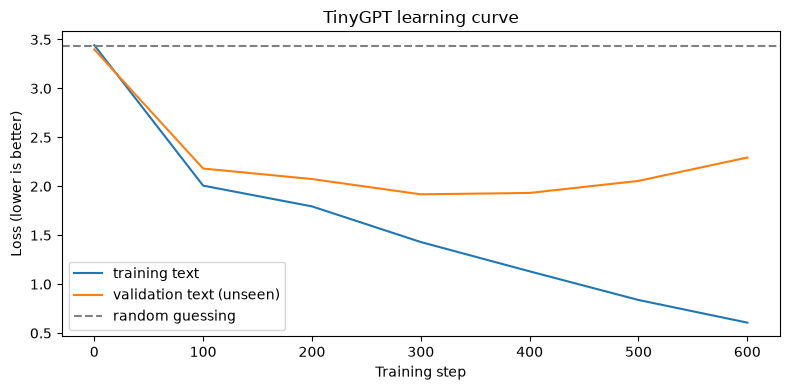

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(history["step"], history["train"], label="training text")
plt.plot(history["step"], history["val"], label="validation text (unseen)")
plt.axhline(math.log(len(chars)), color="grey", linestyle="--", label="random guessing")
plt.title("TinyGPT learning curve"); plt.xlabel("Training step"); plt.ylabel("Loss (lower is better)")
plt.legend(); plt.tight_layout(); plt.show()

**What just happened?**

- Both curves start near the dashed **random guessing** line (the loss you get by giving every character equal probability).
- The **training** loss (blue) keeps falling: the model gets better and better at predicting the rhymes it trains on.
- The **validation** loss (orange, text the model never trains on) falls at first, reaches its lowest point around step 300-400, and then starts to **rise** again.

That rising orange line is **overfitting**: with only about 3 KB of text, the model starts *memorizing* the training rhymes instead of learning general patterns. Real LLMs avoid this mainly by training on vastly more text. A common trick is **early stopping**: keep the model from the step where the validation loss was lowest.

In [22]:
print("AFTER training:\n" + tiny_generate("the ", n=300))

AFTER training:
the behisill.

the se gring fog hen ing fog,
a frog, a goey a fo.

a ca cakee, a sair me, he he bead,
foree raad, a hapy brings he for when is to ance,
and coock, the foreed a night.

the sa cout and keep tran is come.
the win will fall blow, the river tow is will grleep,
the wilk wher itkee when fill g


**What just happened?**

Compare this with the random characters before training. After well under two minutes of training on 3 KB of text, the model has learned:
- **spelling** of many real words (*frog*, *fog*, *hen*, *night*, *river*, *blow*, *fall*),
- **layout**: short lines ending in commas or full stops, and blank lines between verses, just like the rhymes,
- some typical **phrases** (*"the win will fall blow, the river..."* echoes "the wind will blow, the river flow").

It also produces plenty of made-up words and no real meaning: it is a character-level pattern machine with about 62 thousand parameters and a few hundred training steps.

This is *exactly* the same recipe as a real LLM, just millions of times smaller: more parameters, far more text, subword tokens instead of characters, and weeks of training on many GPUs.

### Looking inside: an attention map

Let's feed one line to the trained model and plot the attention weights of the first head in the first block. Row = the character doing the looking, column = the character being looked at.

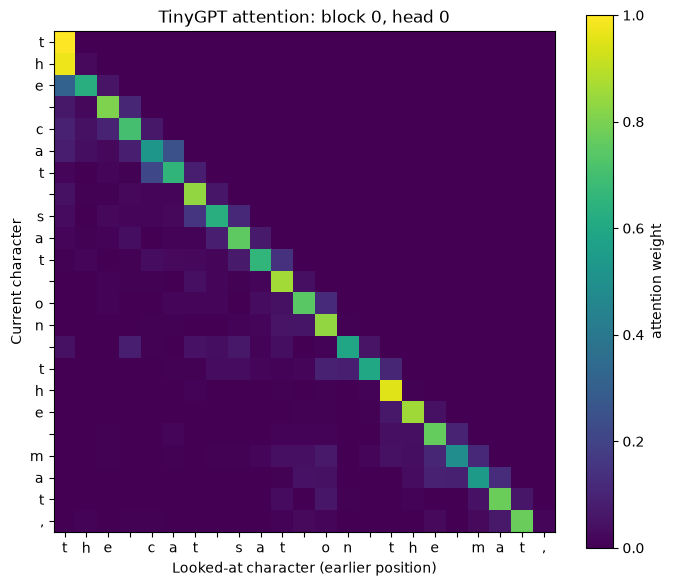

Average attention on itself: 0.12 | on the previous character: 0.73


In [23]:
line = "the cat sat on the mat,"
tiny.eval()                                            # dropout off
with torch.no_grad():
    tiny(torch.tensor([encode(line)]))                 # run once; each head stores its attention weights
attn = tiny.blocks[0].heads[0].attn[0].numpy()         # block 0, head 0, first (only) sequence

plt.figure(figsize=(7, 6))
plt.imshow(attn, cmap="viridis")
plt.xticks(range(len(line)), list(line)); plt.yticks(range(len(line)), list(line))
plt.xlabel("Looked-at character (earlier position)"); plt.ylabel("Current character")
plt.title("TinyGPT attention: block 0, head 0"); plt.colorbar(label="attention weight")
plt.tight_layout(); plt.show()

self_attn = np.mean([attn[i, i] for i in range(len(line))])          # weight on the character itself
prev_attn = np.mean([attn[i, i - 1] for i in range(1, len(line))])    # weight on the character just before
print(f"Average attention on itself: {self_attn:.2f} | on the previous character: {prev_attn:.2f}")

**What just happened?**

- Everything above the diagonal is dark (exactly 0): that is the **causal mask** at work, no character can look at the future.
- The bright cells sit **one step to the left of the diagonal**. The printed numbers confirm it: in our run this head put on average about 0.73 of its attention on the **previous character** and only about 0.12 on the current character itself. It has learned to be a "what was the letter just before me?" detector, which is very useful for spelling words. Nobody programmed this; it emerged from training.
- Other heads and the second block learn other patterns (try changing `heads[0]` to `heads[1]` or `blocks[1]`). The exact pattern depends on training, so your plot may look a little different.

## 5. Limitations you can see live

Because an LLM is a next-token predictor, it produces *plausible-sounding* text, not *verified* text. Let's see three consequences with our small model. We wrap the chat template in a helper first.

In [24]:
def ask(question, system="You are a helpful assistant.", max_new_tokens=40, **sampling):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    prompt_text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return generate(prompt_text, max_new_tokens=max_new_tokens, **sampling)   # greedy unless told otherwise

q1 = "Who won the Nobel Prize in Literature in 2016?"
a1 = ask(q1)
print("Q:", q1); print("A:", a1)
print("Mentions the real winner (Bob Dylan)?", "Dylan" in a1)

Q: Who won the Nobel Prize in Literature in 2016?
A: The Nobel Prize in Literature was awarded to the author of "The Night Circus" in 2016.
Mentions the real winner (Bob Dylan)? False


**What just happened?**

The 2016 Nobel Prize in Literature went to **Bob Dylan**. When we ran this cell, the model instead answered that it was awarded to *"the author of 'The Night Circus'"*, a fantasy novel whose author has never won a Nobel Prize. It said this fluently and confidently, with no hint of doubt. (Your exact wording may differ with other library versions, but this small model usually gets this question wrong; the `Mentions the real winner` line checks it automatically.)

This is called **hallucination**: confident, fluent, wrong. The model is not lying on purpose; it simply produces likely-looking tokens, and a small model has stored few facts reliably. Larger models hallucinate less often, but **all** LLMs can do it.

In [25]:
q2 = "Who was the first person to walk on Mars?"       # a question with a false assumption
print("Q:", q2); print("A:", ask(q2))

Q: Who was the first person to walk on Mars?


A: The first person to walk on Mars was NASA's Curiosity rover, which landed on the red planet on August 6, 2012.


**What just happened?**

No human has walked on Mars. A careful answer would point out the false assumption in the question. When we ran it, the model instead claimed the first "person" was *NASA's Curiosity rover*, which landed in August 2012. The landing date is roughly right, but a rover is not a person and it does not walk: the model mixed a real fact into an answer to a question it should have challenged.

### Fix 1, live: give the model the facts (the idea behind RAG)

**RAG (Retrieval-Augmented Generation)** means: first *retrieve* relevant text (for example with the semantic search you built in the previous notebook), paste it into the prompt, and ask the model to answer *from that text*.

In [26]:
context = "Fact sheet: The 2016 Nobel Prize in Literature was awarded to Bob Dylan, the American singer-songwriter."
rag_q = f"Use only this context to answer.\n\nContext: {context}\n\nQuestion: {q1}"
a_rag = ask(rag_q)
print("A:", a_rag)
print("Mentions Bob Dylan now?", "Dylan" in a_rag)

A: Bob Dylan won the Nobel Prize in Literature in 2016.
Mentions Bob Dylan now? True


**What just happened?**

With the fact pasted into the prompt, the same small model answered correctly (*"Bob Dylan won the Nobel Prize in Literature in 2016."* in our run). The model is much better at **reading** a fact from its context than at **remembering** it from training. That is the whole idea of RAG: you supply the trusted information, the model writes the answer.

### Knowledge cutoff

A model only knows what was in its training data, which was collected up to some date: its **knowledge cutoff**. It also has no clock or internet access unless an app gives it one.

In [27]:
q3 = "What is today's date, and what is the newest version of Python?"
print("Q:", q3); print("A:", ask(q3, max_new_tokens=60))

Q: What is today's date, and what is the newest version of Python?


A: Today's date is 2021-04-01, and the newest version of Python is 3.9.


**What just happened?**

In our run the model replied *"Today's date is 2021-04-01, and the newest version of Python is 3.9."* Both parts are made up from its training data: it has no clock, so it guessed a date, and Python 3.9 (released in 2020) has been followed by several newer versions. Notice that it did not say "I don't know"; it just produced plausible-looking tokens.

The fix is to **give** the model current information: put today's date in the system prompt, or let it call a **tool** (a function such as a search engine, a calculator or a database query that the app runs on the model's behalf).

### Non-determinism

With sampling turned on (temperature > 0), the same question can give different answers.

In [28]:
q4 = "Suggest a name for a pet goldfish. Reply with just the name."
for seed in [0, 1, 2]:
    print(f"seed {seed}:", repr(ask(q4, max_new_tokens=10, temperature=1.0, seed=seed)))
print("seed 0 again:", repr(ask(q4, max_new_tokens=10, temperature=1.0, seed=0)))

seed 0: 'Charlie'


seed 1: 'Goldilocks'


seed 2: 'Spudie'


seed 0 again: 'Charlie'


**What just happened?**

With temperature 1.0, each seed rolled the dice differently, so we got different names (in our run: *Charlie*, *Goldilocks*, *Spudie*). Re-using seed 0 gave *Charlie* again: the randomness is real, but reproducible if you control the seed. Hosted APIs often do not let you fully control this, so the same request can give different answers on different calls.

### How the industry addresses these limitations

| Problem | Common fix | How it helps | Learn more |
|---|---|---|---|
| Hallucination on facts | **RAG** | answer from retrieved, trusted documents | [02_rag/01_rag_fundamentals.ipynb](02_rag/01_rag_fundamentals.ipynb), [19_industry_rag_pipeline.ipynb](19_industry_rag_pipeline.ipynb) |
| Knowledge cutoff, maths, live data | **Tools / agents** | the model asks the app to run a search, calculator or API | [../10_Agents/01_agent_fundamentals.ipynb](../10_Agents/01_agent_fundamentals.ipynb), [../10_Agents/05_mcp_and_tools.ipynb](../10_Agents/05_mcp_and_tools.ipynb) |
| Wrong style, format or domain language | **Fine-tuning** | further training on your own examples | [03_fine_tuning/01_fine_tuning.ipynb](03_fine_tuning/01_fine_tuning.ipynb) |
| Random variation | low temperature, **structured outputs**, evaluation | consistent, checkable answers | [17_structured_outputs.ipynb](17_structured_outputs.ipynb), [08_evaluation/01_llm_evaluation.ipynb](08_evaluation/01_llm_evaluation.ipynb) |

> ⚠️ **Common mistake:** trusting an LLM's answer because it *sounds* confident. Fluency is not evidence. Verify important facts, and prefer designs (RAG, tools) where answers can be traced back to a source.

## 6. How this connects to LLM APIs

In real applications you usually wrap the model behind one small function. Here is a generic `call_llm` using our local model:

In [29]:
def call_llm(prompt, system="You are a helpful assistant.", max_new_tokens=60, temperature=0.0, seed=0):
    # Same interface you would use for a hosted API: text in, text out.
    messages = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
    prompt_text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    n_in = len(tok.encode(prompt_text))                # input tokens (what an API would bill)
    reply = generate(prompt_text, max_new_tokens=max_new_tokens, temperature=temperature, seed=seed)
    n_out = len(tok.encode(reply))                     # output tokens
    return {"text": reply, "input_tokens": n_in, "output_tokens": n_out}

result = call_llm("Rewrite this more politely: 'Send me the report now.'")
print(result)

{'text': 'Please send me the report as soon as possible.', 'input_tokens': 32, 'output_tokens': 10}


**What just happened?**

`call_llm` hides all the details (chat template, tokenization, generation loop) behind one simple function: text in, text and token counts out. In our run it rewrote the message as *"Please send me the report as soon as possible."* and reported about 32 input tokens and 10 output tokens: exactly the numbers a hosted API would bill you for. The rest of your application only needs to know this function.

### The same pattern with a hosted API (text only, not run)

With a hosted provider, only the *inside* of `call_llm` changes: instead of running the model locally, you send the same messages over HTTPS. The sketch below is **generic and not executed**: the URL, model name and field names are placeholders, and every provider has its own exact format and official SDK, so follow its documentation.

```python
import os
import requests

API_KEY = os.environ["LLM_API_KEY"]        # read the key from an environment variable, never hard-code it

def call_llm(prompt, system="You are a helpful assistant.", max_tokens=60, temperature=0.0):
    response = requests.post(
        "https://api.example-llm-provider.com/v1/chat",          # placeholder URL
        headers={"Authorization": f"Bearer {API_KEY}"},
        json={
            "model": "example-model-name",                        # placeholder model name
            "messages": [{"role": "system", "content": system},
                         {"role": "user", "content": prompt}],
            "max_tokens": max_tokens,                             # cap the output length (and cost)
            "temperature": temperature,
        },
        timeout=30,
    )
    response.raise_for_status()                                   # turn HTTP errors into Python errors
    return response.json()                                        # reply text + token usage, in the provider's format
```

Everything you learned still applies: the provider tokenizes your messages with a chat template, the model predicts tokens one at a time with some temperature/top-p setting, and you are billed for input and output tokens.

> ⚠️ **Common mistake:** pasting an API key directly into a notebook or committing it to Git. Set it in your shell (`export LLM_API_KEY=...`) or a `.env` file that is listed in `.gitignore`, and read it with `os.environ`.

## Recap

- An LLM is a **next-token predictor**: tokens in, a probability for every possible next token out. Generation is a loop of predict → pick → append.
- **Logits** are raw scores; **softmax** turns them into probabilities.
- **Greedy** decoding is deterministic; **temperature**, **top-k** and **top-p** control how adventurous sampling is. Temperature 0 means *consistent*, not *correct*.
- **Chat models** see one long token stream built by a **chat template** from system/user/assistant messages.
- The **context window** limits how many tokens fit in one call; APIs bill per token, and multi-turn chats re-send the history, so costs grow each turn.
- A GPT is: **token embedding + positional embedding → transformer blocks (causal self-attention + MLP) → logits**. You trained one in under two minutes.
- Limitations: **hallucination**, **knowledge cutoff** and **non-determinism**. Common fixes: **RAG**, **tools**, **fine-tuning**, low temperature and evaluation.
- Local model or hosted API, the shape is the same: `call_llm(prompt) -> text (+ token counts)`.

## Exercises

**1. (Easy)** Show the top-10 next tokens for the prompt `"The opposite of hot is"`. Is the top token what you expected?

<details><summary>Show solution</summary>

```python
p = torch.softmax(next_token_logits(tok.encode("The opposite of hot is")), -1)
vals, idx = p.topk(10)
for v, i in zip(vals, idx):
    print(f"{tok.decode([int(i)])!r:12} {v:.3f}")
```
</details>

**2. (Easy)** Run `generate(start, temperature=3.0, seed=0)`. What happens to the text, and why?

<details><summary>Show solution</summary>

```python
print(generate(start, temperature=3.0, seed=0))
```
Dividing the logits by 3 flattens the distribution so much that rare, unrelated tokens get picked often, so the text quickly becomes nonsense (often mixing languages and symbols).
</details>

**3. (Medium)** Using the made-up prices, how much would 50,000 calls cost if each call sends a 2,000-token document plus a 50-token question and gets a 200-token answer? What if you only sent the 3 most relevant 200-token chunks of the document instead (a RAG-style prompt)?

<details><summary>Show solution</summary>

```python
full = 50_000 * cost(2_000 + 50, 200)
rag = 50_000 * cost(3 * 200 + 50, 200)
print(f"Whole document: ${full:.2f}   RAG chunks: ${rag:.2f}")
```
With these made-up prices: about $71.25 vs $36.25. The output cost is the same, but the input cost drops by roughly two-thirds.
</details>

**4. (Medium)** Train TinyGPT for longer (e.g. `MAX_STEPS = 3000`) or make it bigger (`EMBED = 128`). Watch the validation loss: does it keep improving, or does it start rising while the training loss falls?

<details><summary>Show solution</summary>

Change the numbers, re-run the model-definition cell and every cell after it. With such a small text, a bigger or longer-trained model soon starts **overfitting**: training loss keeps falling (it memorizes the rhymes) while validation loss stops improving or rises. More data is the real fix.
</details>

**5. (Harder)** Extend `call_llm` so it remembers the conversation: keep a `history` list, append each user message and assistant reply, and send the whole list each time. Ask "My name is Sam." and then "What is my name?".

<details><summary>Show solution</summary>

```python
chat_history = [{"role": "system", "content": "You are a helpful assistant."}]

def chat(user_message, max_new_tokens=40):
    chat_history.append({"role": "user", "content": user_message})
    prompt_text = tok.apply_chat_template(chat_history, tokenize=False, add_generation_prompt=True)
    reply = generate(prompt_text, max_new_tokens=max_new_tokens)
    chat_history.append({"role": "assistant", "content": reply})
    return reply

print(chat("My name is Sam."))
print(chat("What is my name?"))
```
The model "remembers" only because we re-send the history. That is also why long chats cost more tokens.
</details>

## Where to go next

In this folder ([08_LLM](.)):
- [01_chatbots/01_chatbots.ipynb](01_chatbots/01_chatbots.ipynb): build chatbots with conversation memory
- [02_rag/](02_rag/): [01_rag_fundamentals.ipynb](02_rag/01_rag_fundamentals.ipynb), [02_advanced_rag.ipynb](02_rag/02_advanced_rag.ipynb), and more retrieval techniques
- [03_fine_tuning/01_fine_tuning.ipynb](03_fine_tuning/01_fine_tuning.ipynb): adapt a model to your data
- [04_different_llms/01_llm_landscape.ipynb](04_different_llms/01_llm_landscape.ipynb) and [05_slms/01_small_language_models.ipynb](05_slms/01_small_language_models.ipynb): the model landscape and small models
- [19_industry_rag_pipeline.ipynb](19_industry_rag_pipeline.ipynb): an end-to-end RAG pipeline
- [20_industry_llm_application_patterns.ipynb](20_industry_llm_application_patterns.ipynb): common patterns for real LLM applications
- Notes: [notes/08_LLM.md](notes/08_LLM.md)

Related:
- [../09_Prompt_Engineering/01_basics.ipynb](../09_Prompt_Engineering/01_basics.ipynb): writing better prompts
- [../05_Deep_Learning/05_transformers_architecture.ipynb](../05_Deep_Learning/05_transformers_architecture.ipynb): the transformer in more depth
- [../10_Agents/01_agent_fundamentals.ipynb](../10_Agents/01_agent_fundamentals.ipynb): LLMs that use tools
- Back to the previous step: [../07_NLP/00_start_here_text_to_numbers.ipynb](../07_NLP/00_start_here_text_to_numbers.ipynb)